# 4회차 스터디


In [2]:
# 기존 라이브러리 - 복붙하세요. ctrl + c, ctrl + v
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'   # 한글 폰트 설정: Windows
# plt.rcParams['font.family'] = 'AppleSDGothicNeo'   # 한글 폰트 설정: Mac
plt.rcParams['axes.unicode_minus'] = False      # 마이너스 기호 깨짐 방지

# 분류모델

In [15]:
# 펭귄 데이터
df = sns.load_dataset('penguins')

In [16]:
df.sample(5)
# 데이터의 구조, 형태를 살펴본다.

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
59,Adelie,Biscoe,37.6,19.1,194.0,3750.0,Male
134,Adelie,Dream,38.1,17.6,187.0,3425.0,Female
112,Adelie,Biscoe,39.7,17.7,193.0,3200.0,Female
288,Gentoo,Biscoe,43.5,14.2,220.0,4700.0,Female
155,Chinstrap,Dream,45.4,18.7,188.0,3525.0,Female


- species : 종 (종속, 타겟 데이터)
- bill_length_mm	bill_depth_mm	flipper_length_mm	body_mass_g
  - 연속형 데이터, 수치 범위가 피쳐별로 상이함
  - 정규화가 필요할 수 있다.	
- island, sex : 범주 데이터
  - 텍스트로 되어있어 인코딩이 필요

## 1. EDA

In [18]:
# 수치 데이터의 EDA
df.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


<Axes: >

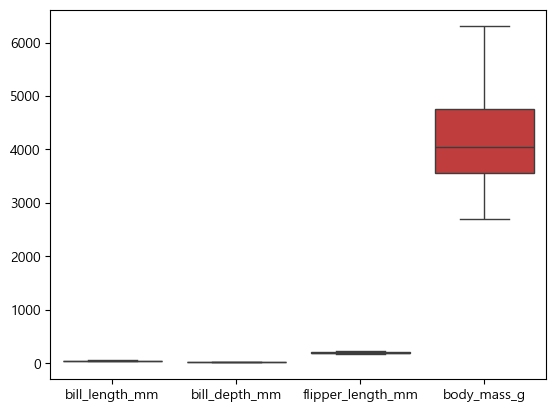

In [32]:
sns.boxplot(data=df)
# plt.yscale('log') # 로그스케일로 보아야 잘 보임

4개의 수치형 변수는 최소 최대값, 평균, 편차 등 모두 다름

<Axes: xlabel='species', ylabel='count'>

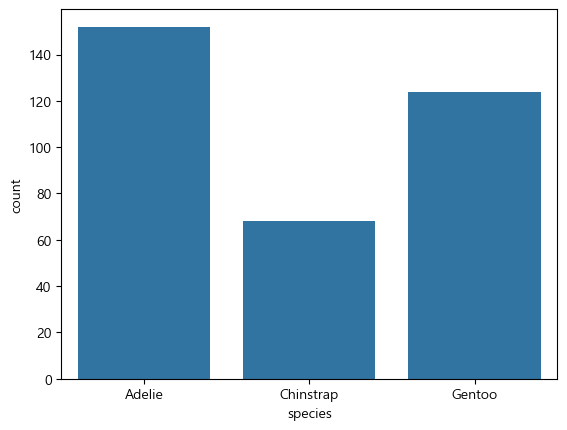

In [36]:
# 범주 데이터의 분포 확인
sns.countplot(data=df, x='species')

<Axes: xlabel='island', ylabel='count'>

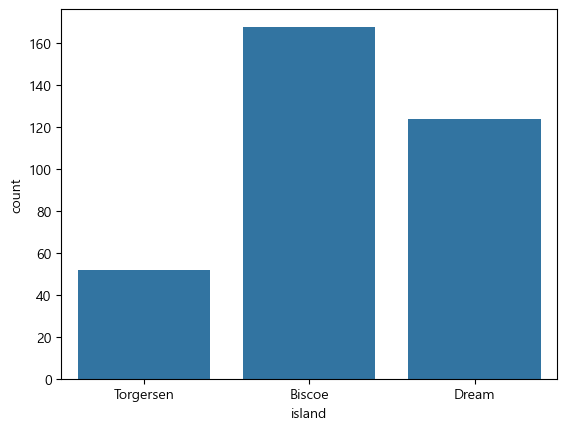

In [37]:
# 범주 데이터의 분포 확인
sns.countplot(data=df, x='island')

<Axes: xlabel='sex', ylabel='count'>

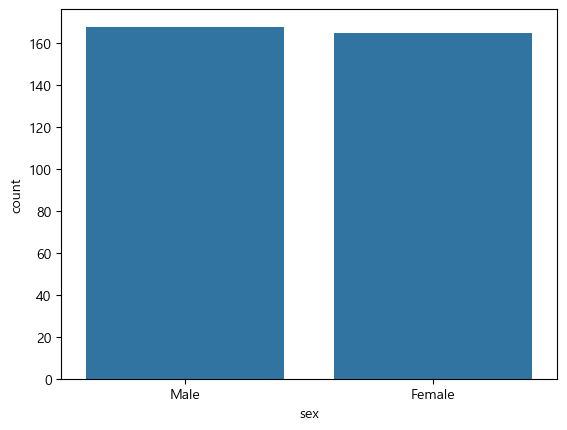

In [38]:
# 범주 데이터의 분포 확인
sns.countplot(data=df, x='sex')

- 약간의 불균형은 있으나 심각한 수준은 아님(심한 불균형은 0%대를 말한다.)


일부 데이터에 결측이 있음



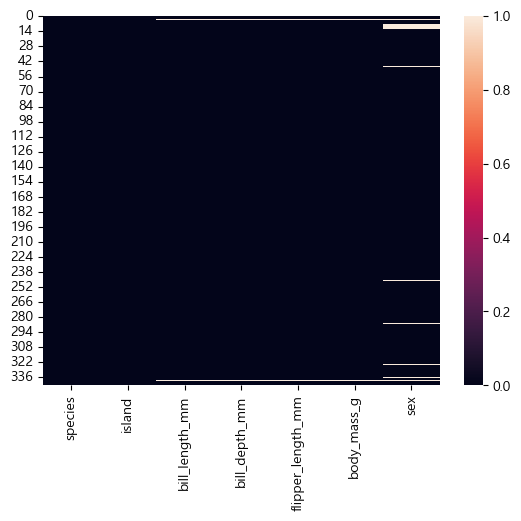

In [14]:
#결측값 확인
sns.heatmap(df.isnull())
print('''
일부 데이터에 결측이 있음
''')

## 2. 데이터 분리

In [98]:
# 종속변수
y = df['species']
# 독립변수
X = df.drop(columns='species')
# X = df.drop(columns=['species', 'island', 'sex']) # 범주형 컬럼 제거
y.shape, X.shape

((344,), (344, 6))

In [99]:
from sklearn.model_selection import train_test_split
# train_test_split() 함수로 데이터를 학습용과 테스트용으로 나눈다.
train_X, test_X, train_y, test_y = train_test_split(
    X, y,
    test_size=0.3,
    stratify=y,    
    random_state=42)
train_X.shape, test_X.shape, train_y.shape, test_y.shape

((240, 6), (104, 6), (240,), (104,))

## 3. 전처리
### 결측값 처리

In [100]:
# 컬럼 종류 구분
# df.columns
num_cols = ['bill_length_mm', 'bill_depth_mm','flipper_length_mm', 'body_mass_g']
cat_cols = ['island', 'sex']

In [101]:
# 결측값 처리
from sklearn.impute import SimpleImputer
si = SimpleImputer(strategy='median') # 중앙값으로 결측값을 대체
train_X[num_cols] = si.fit_transform(train_X[num_cols])
test_X [num_cols] = si.    transform(test_X [num_cols])

In [102]:
# 카테고리 컬럼 데이터의 결측값 처리
si = SimpleImputer(strategy='most_frequent') # 최빈값으로 결측값을 대체
train_X[cat_cols] = si.fit_transform(train_X[cat_cols])
test_X [cat_cols] = si.    transform(test_X [cat_cols])

In [103]:
# 임퓨팅 전후를 히트맵으로 확인해보자
# sns.heatmap(df.isnull())
# sns.heatmap(train_X.isnull())
# sns.heatmap(test_X.isnull())

### 정규화

In [104]:
from sklearn.preprocessing import StandardScaler
ss = StandardScaler()
train_X[num_cols] = ss.fit_transform(train_X[num_cols])
test_X [num_cols] = ss.    transform(test_X [num_cols])

In [105]:
# 전후비교
# X.describe()
train_X.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,2.400000e+02,2.400000e+02,2.400000e+02,240.000000
mean,-6.513308e-16,7.919591e-16,-5.477100e-16,0.000000
std,1.002090e+00,1.002090e+00,1.002090e+00,1.002090
min,-1.998938e+00,-1.977194e+00,-2.083501e+00,-1.920385
25%,-8.397397e-01,-9.052580e-01,-7.927046e-01,-0.793049
50%,6.588413e-02,6.922920e-02,-2.907281e-01,-0.166752
75%,8.809456e-01,8.000946e-01,8.566468e-01,0.710065
max,2.800868e+00,2.115652e+00,2.147444e+00,2.588958


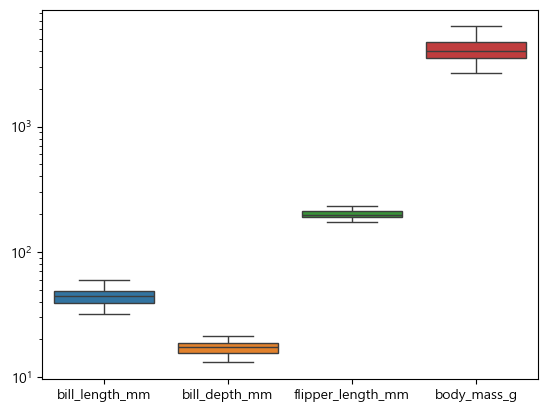

In [106]:
sns.boxplot(data=X)
plt.yscale('log') # 로그스케일로 보아야 잘 보임

<Axes: >

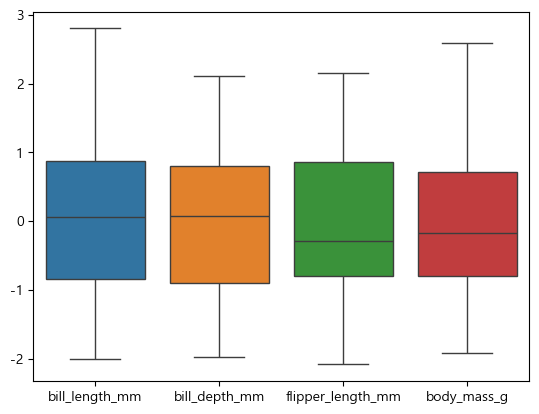

In [107]:
sns.boxplot(data=train_X)

### 범주 데이터 인코딩

In [108]:
from sklearn.preprocessing import OneHotEncoder
ohe = OneHotEncoder(sparse_output=False,drop='first', handle_unknown='ignore')
# 에러가 나는 경우 sparse=False로 대체
train_cat = ohe.fit_transform(train_X[cat_cols])
test_cat  = ohe.    transform(test_X [cat_cols])

In [109]:
# 1개의 컬럼이 여러개의 컬럼으로 변환되었는지 확인
train_cat.shape, test_cat.shape
# df[col] 방식으로 직접 넣을 수는 없음

((240, 3), (104, 3))

In [110]:
train_cat = pd.DataFrame(train_cat, columns=ohe.get_feature_names_out(cat_cols), index=train_X.index)
test_cat  = pd.DataFrame(test_cat , columns=ohe.get_feature_names_out(cat_cols), index=test_X.index)
train_X = pd.concat([train_X.drop(columns=cat_cols), train_cat], axis=1)
test_X  = pd.concat([test_X .drop(columns=cat_cols), test_cat ], axis=1)

In [111]:
train_X.shape, test_X.shape

((240, 7), (104, 7))

### 모델 훈련 및 스코어링

In [112]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(max_iter=1000)
lr.fit(train_X, train_y)
lr.score(train_X, train_y), lr.score(test_X, test_y)

(0.9958333333333333, 0.9903846153846154)

In [113]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(random_state=42)
dt.fit(train_X, train_y)
dt.score(train_X, train_y), dt.score(test_X, test_y)

(1.0, 0.9807692307692307)

In [114]:
from sklearn.svm import SVC
svm = SVC()
svm.fit(train_X, train_y)
svm.score(train_X, train_y), svm.score(test_X, test_y)

(0.9958333333333333, 0.9903846153846154)

### 분류모델 confusion matrix 혼동행렬과 성능지표 종합

In [123]:
from sklearn.metrics import confusion_matrix, classification_report
y_pred = lr.predict(test_X)
print(confusion_matrix(test_y, y_pred))

[[46  0  0]
 [ 0 21  0]
 [ 1  0 36]]


In [119]:
from sklearn.metrics import classification_report
y_pred = lr.predict(test_X)
print(classification_report(test_y, y_pred))

              precision    recall  f1-score   support

      Adelie       0.98      1.00      0.99        46
   Chinstrap       1.00      1.00      1.00        21
      Gentoo       1.00      0.97      0.99        37

    accuracy                           0.99       104
   macro avg       0.99      0.99      0.99       104
weighted avg       0.99      0.99      0.99       104



# 분류모델 _ 타이타닉 데이터셋

In [125]:
# 펭귄 데이터
df = sns.load_dataset('titanic')

In [126]:
df.sample(5)
# 데이터의 구조, 형태를 살펴본다.

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
861,0,2,male,21.0,1,0,11.5000,S,Second,man,True,NaN,Southampton,no,False
392,0,3,male,28.0,2,0,7.9250,S,Third,man,True,NaN,Southampton,no,False
332,0,1,male,38.0,0,1,153.4625,S,First,man,True,C,Southampton,no,False
853,1,1,female,16.0,0,1,39.4000,S,First,woman,False,D,Southampton,yes,False
175,0,3,male,18.0,1,1,7.8542,S,Third,man,True,NaN,Southampton,no,False


- species : 종 (종속, 타겟 데이터)
- bill_length_mm	bill_depth_mm	flipper_length_mm	body_mass_g
  - 연속형 데이터, 수치 범위가 피쳐별로 상이함
  - 정규화가 필요할 수 있다.	
- island, sex : 범주 데이터
  - 텍스트로 되어있어 인코딩이 필요

## 1. EDA

In [127]:
# 수치 데이터의 EDA
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


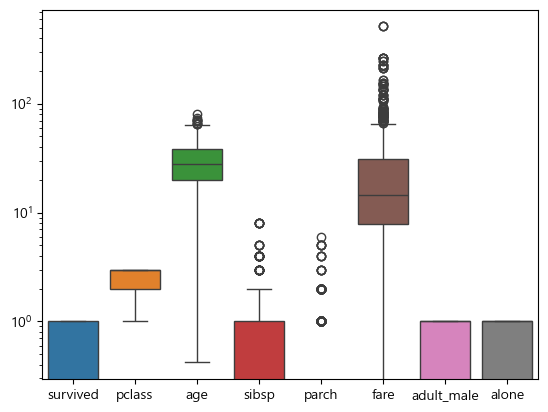

In [129]:
sns.boxplot(data=df)
plt.yscale('log') # 로그스케일로 보아야 잘 보임

4개의 수치형 변수는 최소 최대값, 평균, 편차 등 모두 다름

- 약간의 불균형은 있으나 심각한 수준은 아님(심한 불균형은 0%대를 말한다.)


일부 데이터에 결측이 있음



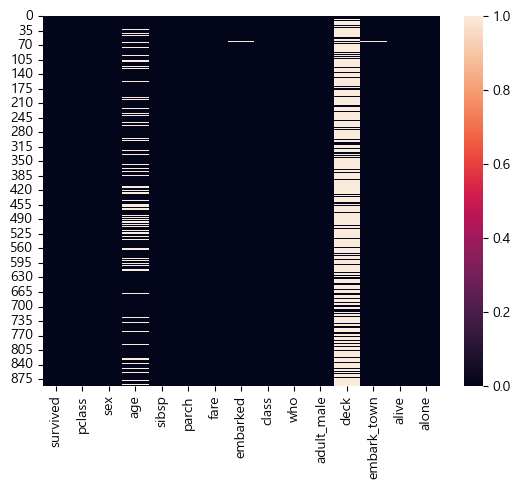

In [131]:
#결측값 확인
sns.heatmap(df.isnull())
print('''
일부 데이터에 결측이 있음
''')

## 2. 데이터 분리

In [132]:
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='object')

In [133]:
# 종속변수
y = df['survived']
# 독립변수
X = df.drop(columns=['survived','alive'])
# X = df.drop(columns=['survived', 'island', 'sex']) # 범주형 컬럼 제거
y.shape, X.shape

((891,), (891, 13))

In [134]:
from sklearn.model_selection import train_test_split
# train_test_split() 함수로 데이터를 학습용과 테스트용으로 나눈다.
train_X, test_X, train_y, test_y = train_test_split(
    X, y,
    test_size=0.3,
    stratify=y,    
    random_state=42)
train_X.shape, test_X.shape, train_y.shape, test_y.shape

((623, 13), (268, 13), (623,), (268,))

## 3. 전처리
### 결측값 처리

In [138]:
# 컬럼 종류 구분
print(df.columns)
display(df.head(5))
num_cols = ['pclass', 'age','sibsp', 'parch', 'fare']
cat_cols = ['sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town','alone']

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='object')


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [143]:
# 결측값 처리
from sklearn.impute import SimpleImputer
si = SimpleImputer(strategy='median') # 중앙값으로 결측값을 대체
train_X[num_cols] = si.fit_transform(train_X[num_cols])
test_X [num_cols] = si.    transform(test_X [num_cols])

In [144]:
# 카테고리 컬럼 데이터의 결측값 처리
si = SimpleImputer(strategy='most_frequent') # 최빈값으로 결측값을 대체
train_X[cat_cols] = si.fit_transform(train_X[cat_cols])
test_X [cat_cols] = si.    transform(test_X [cat_cols])

In [145]:
# 임퓨팅 전후를 히트맵으로 확인해보자
# sns.heatmap(df.isnull())
# sns.heatmap(train_X.isnull())
# sns.heatmap(test_X.isnull())

### 정규화

In [146]:
from sklearn.preprocessing import StandardScaler
ss = StandardScaler()
train_X[num_cols] = ss.fit_transform(train_X[num_cols])
test_X [num_cols] = ss.    transform(test_X [num_cols])

In [147]:
# 전후비교
# X.describe()
train_X.describe()

,pclass,age,sibsp,parch,fare
count,6.230000e+02,6.230000e+02,6.230000e+02,6.230000e+02,6.230000e+02
mean,-2.109958e-16,2.794269e-16,2.851295e-17,4.989766e-18,-1.083492e-16
std,1.000804e+00,1.000804e+00,1.000804e+00,1.000804e+00,1.000804e+00
min,-1.589202e+00,-2.257007e+00,-4.746823e-01,-4.486645e-01,-6.469544e-01
25%,-3.847338e-01,-6.017845e-01,-4.746823e-01,-4.486645e-01,-4.815005e-01
50%,8.197343e-01,-6.487265e-02,-4.746823e-01,-4.486645e-01,-3.640664e-01
75%,8.197343e-01,4.720392e-01,5.629566e-01,-4.486645e-01,-1.831444e-02
max,8.197343e-01,3.846914e+00,7.826429e+00,6.687965e+00,1.008873e+01


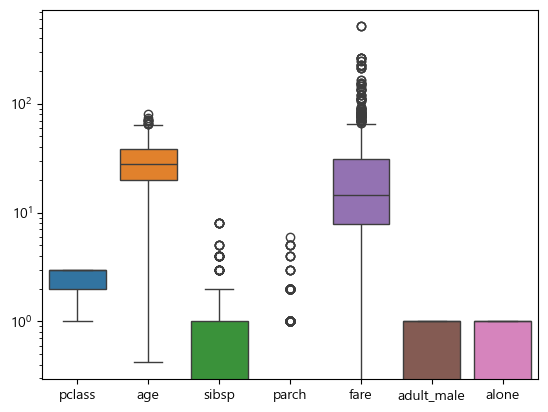

In [148]:
sns.boxplot(data=X)
plt.yscale('log') # 로그스케일로 보아야 잘 보임

<Axes: >

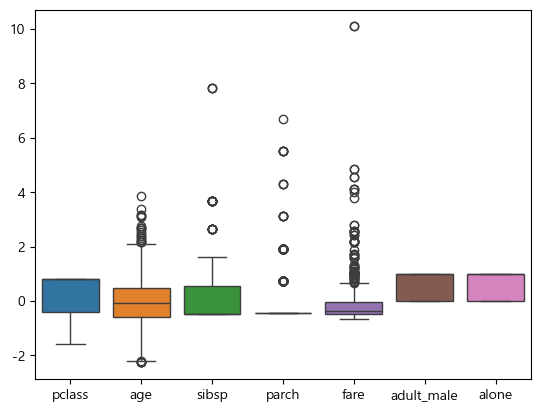

In [149]:
sns.boxplot(data=train_X)

### 범주 데이터 인코딩

In [150]:
from sklearn.preprocessing import OneHotEncoder
ohe = OneHotEncoder(sparse_output=False,drop='first', handle_unknown='ignore')
# 에러가 나는 경우 sparse=False로 대체
train_cat = ohe.fit_transform(train_X[cat_cols])
test_cat  = ohe.    transform(test_X [cat_cols])

In [151]:
# 1개의 컬럼이 여러개의 컬럼으로 변환되었는지 확인
train_cat.shape, test_cat.shape
# df[col] 방식으로 직접 넣을 수는 없음

((623, 17), (268, 17))

In [152]:
train_cat = pd.DataFrame(train_cat, columns=ohe.get_feature_names_out(cat_cols), index=train_X.index)
test_cat  = pd.DataFrame(test_cat , columns=ohe.get_feature_names_out(cat_cols), index=test_X.index)
train_X = pd.concat([train_X.drop(columns=cat_cols), train_cat], axis=1)
test_X  = pd.concat([test_X .drop(columns=cat_cols), test_cat ], axis=1)

In [153]:
train_X.shape, test_X.shape

((623, 22), (268, 22))

### 모델 훈련 및 스코어링

In [154]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(max_iter=1000)
lr.fit(train_X, train_y)
lr.score(train_X, train_y), lr.score(test_X, test_y)

(0.8362760834670947, 0.8208955223880597)

In [243]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(max_depth=500)
dt.fit(train_X, train_y)
dt.score(train_X, train_y), dt.score(test_X, test_y)

(0.9775280898876404, 0.7985074626865671)

In [218]:
from sklearn.svm import SVC
svm = SVC()
svm.fit(train_X, train_y)
svm.score(train_X, train_y), svm.score(test_X, test_y)

(0.8491171749598716, 0.8097014925373134)

In [159]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier()
rf.fit(train_X, train_y)
rf.score(train_X, train_y), rf.score(test_X, test_y)

(0.9775280898876404, 0.8022388059701493)

In [163]:
from sklearn.ensemble import GradientBoostingClassifier
gb = GradientBoostingClassifier()
gb.fit(train_X, train_y)
gb.score(train_X, train_y), gb.score(test_X, test_y)

(0.9085072231139647, 0.8171641791044776)

### 분류모델 confusion matrix 혼동행렬과 성능지표 종합

In [181]:
from sklearn.metrics import confusion_matrix, classification_report
y_pred = rf.predict(test_X)
print(confusion_matrix(test_y, y_pred))

[[141  24]
 [ 29  74]]


In [161]:
from sklearn.metrics import classification_report
y_pred = rf.predict(test_X)
print(classification_report(test_y, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.85      0.84       165
           1       0.76      0.72      0.74       103

    accuracy                           0.80       268
   macro avg       0.79      0.79      0.79       268
weighted avg       0.80      0.80      0.80       268



In [166]:
from sklearn.metrics import classification_report
y_pred = lr.predict(test_X)
print(confusion_matrix(test_y, y_pred))
print(classification_report(test_y, y_pred))

[[140  25]
 [ 23  80]]
              precision    recall  f1-score   support

           0       0.86      0.85      0.85       165
           1       0.76      0.78      0.77       103

    accuracy                           0.82       268
   macro avg       0.81      0.81      0.81       268
weighted avg       0.82      0.82      0.82       268



In [165]:
from sklearn.metrics import classification_report
y_pred = gb.predict(test_X)
print(confusion_matrix(test_y, y_pred))
print(classification_report(test_y, y_pred))

[[150  15]
 [ 34  69]]
              precision    recall  f1-score   support

           0       0.82      0.91      0.86       165
           1       0.82      0.67      0.74       103

    accuracy                           0.82       268
   macro avg       0.82      0.79      0.80       268
weighted avg       0.82      0.82      0.81       268



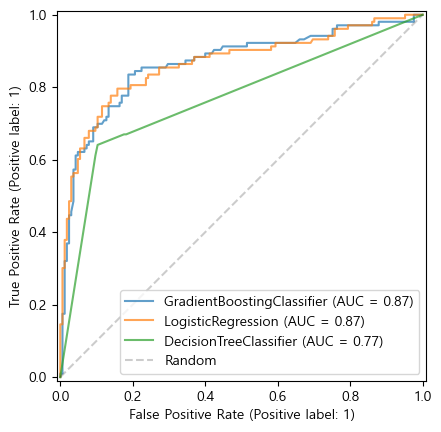

In [244]:
from sklearn.metrics import roc_auc_score, roc_curve, RocCurveDisplay
fig, ax = plt.subplots()

y_proba = gb.predict_proba(test_X)[:,1]
RocCurveDisplay.from_estimator(gb, test_X, test_y, ax=ax, alpha=0.7)

y_proba = lr.predict_proba(test_X)[:,1]
RocCurveDisplay.from_estimator(lr, test_X, test_y, ax=ax, alpha=0.7)

y_proba = dt.predict_proba(test_X)[:,1]
RocCurveDisplay.from_estimator(dt, test_X, test_y, ax=ax, alpha=0.7)

plt.plot([0, 1], [0, 1], 'k--', label='Random', alpha=0.2)
plt.legend()
plt.show()

In [251]:
# by gpt
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.metrics import (
    roc_curve, roc_auc_score, confusion_matrix,
    accuracy_score, precision_score, recall_score, f1_score
)

# 1. 모델과 임계값
models = {'LR': lr, 'GB': gb}
thresholds = np.linspace(0, 1, 101)
metrics = ['Accuracy', 'Precision', 'Recall', 'F1']
colors = {
    'Accuracy': '#6366f1',
    'Precision': '#16a34a',
    'Recall': '#ef4444',
    'F1': '#f59e0b'
}
model_colors = {'LR': '#2563eb', 'GB': '#ea580c'}

# 2. 임계값별 성능 계산
results = {}

for name, model in models.items():
    prob = model.predict_proba(test_X)[:, 1]
    fpr, tpr, _ = roc_curve(test_y, prob)

    result = {
        'fpr': fpr,
        'tpr': tpr,
        'auc': roc_auc_score(test_y, prob),
        'points': [],
        'metrics': {m: [] for m in metrics}
    }

    for t in thresholds:
        pred = (prob >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(
            test_y, pred, labels=[0, 1]
        ).ravel()

        result['points'].append((
            fp / (fp + tn),
            tp / (tp + fn)
        ))
        result['metrics']['Accuracy'].append(
            accuracy_score(test_y, pred)
        )
        result['metrics']['Precision'].append(
            precision_score(test_y, pred, zero_division=0)
        )
        result['metrics']['Recall'].append(
            recall_score(test_y, pred, zero_division=0)
        )
        result['metrics']['F1'].append(
            f1_score(test_y, pred, zero_division=0)
        )

    results[name] = result

# 3. 그래프 구성
fig = make_subplots(
    rows=1, cols=3,
    subplot_titles=[
        'ROC Curve',
        'Logistic Regression',
        'Gradient Boosting'
    ],
    horizontal_spacing=0.09
)

# ROC 곡선
for name in models:
    r = results[name]
    fig.add_trace(
        go.Scatter(
            x=r['fpr'], y=r['tpr'],
            mode='lines',
            name=f'{name} (AUC={r["auc"]:.3f})',
            line=dict(color=model_colors[name], width=2)
        ),
        row=1, col=1
    )

# 무작위 분류 기준선
fig.add_trace(
    go.Scatter(
        x=[0, 1], y=[0, 1],
        mode='lines',
        name='Random',
        line=dict(color='gray', dash='dash')
    ),
    row=1, col=1
)

# 성능지표 곡선
for col, name in [(2, 'LR'), (3, 'GB')]:
    for m in metrics:
        fig.add_trace(
            go.Scatter(
                x=thresholds,
                y=results[name]['metrics'][m],
                mode='lines',
                name=m,
                line=dict(color=colors[m]),
                showlegend=(col == 2)
            ),
            row=1, col=col
        )

# 4. 슬라이더로 이동할 점
initial = 50  # Threshold = 0.50
moving_indices = []

# ROC 위의 이동 점
for name in models:
    x, y = results[name]['points'][initial]
    fig.add_trace(
        go.Scatter(
            x=[x], y=[y],
            mode='markers',
            marker=dict(
                size=13,
                color=model_colors[name],
                line=dict(color='white', width=2)
            ),
            showlegend=False
        ),
        row=1, col=1
    )
    moving_indices.append(len(fig.data) - 1)

# 성능지표 위의 이동 점
for col, name in [(2, 'LR'), (3, 'GB')]:
    for m in metrics:
        fig.add_trace(
            go.Scatter(
                x=[thresholds[initial]],
                y=[results[name]['metrics'][m][initial]],
                mode='markers',
                marker=dict(size=11, color=colors[m]),
                showlegend=False
            ),
            row=1, col=col
        )
        moving_indices.append(len(fig.data) - 1)

# 5. 임계값별 프레임
def frame_data(i):
    data = []

    for name in models:
        x, y = results[name]['points'][i]
        data.append(go.Scatter(x=[x], y=[y]))

    for name in ['LR', 'GB']:
        for m in metrics:
            data.append(go.Scatter(
                x=[thresholds[i]],
                y=[results[name]['metrics'][m][i]]
            ))

    return data

def title_text(i):
    parts = []
    for name in models:
        r = results[name]['metrics']
        parts.append(
            f'{name}: ACC {r["Accuracy"][i]:.2f}, '
            f'P {r["Precision"][i]:.2f}, '
            f'R {r["Recall"][i]:.2f}, '
            f'F1 {r["F1"][i]:.2f}'
        )
    return (
        f'Threshold = {thresholds[i]:.2f}'
        + '<br><sup>' + ' | '.join(parts) + '</sup>'
    )

fig.frames = [
    go.Frame(
        name=str(i),
        data=frame_data(i),
        traces=moving_indices,
        layout=go.Layout(title=dict(text=title_text(i)))
    )
    for i in range(len(thresholds))
]

# 6. 슬라이더 설정
steps = [
    dict(
        method='animate',
        args=[
            [str(i)],
            dict(
                mode='immediate',
                frame=dict(duration=0, redraw=False),
                transition=dict(duration=0)
            )
        ],
        label=f'{t:.2f}'
    )
    for i, t in enumerate(thresholds)
]

fig.update_layout(
    title=title_text(initial),
    width=1500,
    height=570,
    sliders=[dict(
        active=initial,
        currentvalue=dict(prefix='Threshold: '),
        steps=steps,
        x=0.1,
        len=0.8,
        y=-0.12
    )],
    margin=dict(t=110, b=130)
)

for col in [1, 2, 3]:
    fig.update_xaxes(range=[0, 1], row=1, col=col)
    fig.update_yaxes(range=[0, 1.03], row=1, col=col)

fig.update_xaxes(title_text='FPR', row=1, col=1)
fig.update_yaxes(title_text='TPR', row=1, col=1)

for col in [2, 3]:
    fig.update_xaxes(title_text='Threshold', row=1, col=col)

fig.show()

In [252]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.metrics import roc_curve, roc_auc_score

models = {'LR': lr, 'GB': gb}
colors = {'LR': 'royalblue', 'GB': 'darkorange'}

fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=['ROC Curve & Youden Point',
                    'Youden J vs Threshold']
)

# 무작위 분류 기준선
fig.add_trace(
    go.Scatter(
        x=[0, 1], y=[0, 1],
        mode='lines', name='Random',
        line=dict(color='gray', dash='dash')
    ),
    row=1, col=1
)

for name, model in models.items():

    prob = model.predict_proba(test_X)[:, 1]
    fpr, tpr, thresholds = roc_curve(
        test_y, prob, drop_intermediate=False
    )

    # Youden J 계산
    j = tpr - fpr

    # 유효한 임계값에서 최댓값 탐색
    valid = np.isfinite(thresholds) & (thresholds <= 1)
    best_idx = np.argmax(np.where(valid, j, -np.inf))

    best_fpr = fpr[best_idx]
    best_tpr = tpr[best_idx]
    best_t = thresholds[best_idx]
    best_j = j[best_idx]

    auc = roc_auc_score(test_y, prob)

    # ① ROC 곡선
    fig.add_trace(
        go.Scatter(
            x=fpr, y=tpr,
            mode='lines',
            name=f'{name} AUC={auc:.3f}',
            line=dict(color=colors[name], width=2)
        ),
        row=1, col=1
    )

    # 요든 최적점
    fig.add_trace(
        go.Scatter(
            x=[best_fpr], y=[best_tpr],
            mode='markers',
            marker=dict(
                size=12, color=colors[name],
                symbol='star'
            ),
            name=f'{name} Optimal ({best_t:.3f})'
        ),
        row=1, col=1
    )

    # 대각선과 최적점 사이 수직 거리
    fig.add_trace(
        go.Scatter(
            x=[best_fpr, best_fpr],
            y=[best_fpr, best_tpr],
            mode='lines',
            line=dict(
                color=colors[name],
                dash='dot', width=3
            ),
            showlegend=False
        ),
        row=1, col=1
    )

    # ② Threshold별 Youden J
    fig.add_trace(
        go.Scatter(
            x=thresholds[valid],
            y=j[valid],
            mode='lines',
            name=f'{name} Youden J',
            line=dict(color=colors[name]),
            showlegend=False
        ),
        row=1, col=2
    )

    # 최적 임계값 표시
    fig.add_trace(
        go.Scatter(
            x=[best_t], y=[best_j],
            mode='markers+text',
            marker=dict(size=11, color=colors[name]),
            text=[f'{name}: {best_t:.3f}'],
            textposition='top center',
            showlegend=False
        ),
        row=1, col=2
    )

    print(
        f'{name}: Threshold={best_t:.3f}, '
        f'TPR={best_tpr:.3f}, '
        f'FPR={best_fpr:.3f}, '
        f'Youden J={best_j:.3f}'
    )

fig.update_xaxes(title_text='FPR', range=[0, 1], row=1, col=1)
fig.update_yaxes(title_text='TPR', range=[0, 1.02], row=1, col=1)
fig.update_xaxes(title_text='Threshold', row=1, col=2)
fig.update_yaxes(title_text='Youden J', row=1, col=2)

fig.update_layout(
    width=1200,
    height=520,
    template='plotly_white'
)

fig.show()

LR: Threshold=0.482, TPR=0.796, FPR=0.158, Youden J=0.639
GB: Threshold=0.308, TPR=0.835, FPR=0.188, Youden J=0.647
